In [35]:
import os
import anndata as ad
import pandas as pd

spatial_dir = (
    "/work/magroup/skrieger/Syndri/data/xenium_noise_experiment/"
)

files = sorted(
    f
    for f in os.listdir(spatial_dir)
    if f.endswith("1pct.h5ad") and f.startswith("cosmx_nsclc")
)

result_dfs = []

for f in files:
    adata = ad.read_h5ad(
        os.path.join(spatial_dir, f),
        backed="r",
    )
    # adata = adata[adata.obs['rctd_spot_class'].isin(['singlet','doublet_certain'])]

    sample_replicate = "_".join(f.split("_")[2:3])

    for annotation_method in [
        "cell_type",
        "split_X_primary_cell_type",
    ]:
        if annotation_method not in adata.obs.columns:
            print(
                f"Warning: {annotation_method} not found in {f}"
            )
            continue

        counts = (
            adata.obs[annotation_method]
            .value_counts(dropna=False)
            .rename_axis("cell_type")
            .reset_index(name="count")
        )

        counts["sample_replicate"] = sample_replicate
        counts["annotation_method"] = annotation_method

        result_dfs.append(counts)

    adata.file.close()

results = pd.concat(
    result_dfs,
    ignore_index=True,
)

results["is_tcell"] = (
    results["cell_type"]
    .astype("string")
    .str.contains(r"\bT\b|T cell", case=False, na=False)
)

print(results)

       cell_type  count sample_replicate          annotation_method  is_tcell
0          tumor  18512           Lung12                  cell_type     False
1     neutrophil  16699           Lung12                  cell_type     False
2     fibroblast  16548           Lung12                  cell_type     False
3    plasmablast   5045           Lung12                  cell_type     False
4    endothelial   3121           Lung12                  cell_type     False
..           ...    ...              ...                        ...       ...
249       T CD8+   1509       Lung9-Rep2  split_X_primary_cell_type      True
250   epithelial   1425       Lung9-Rep2  split_X_primary_cell_type     False
251         Treg   1314       Lung9-Rep2  split_X_primary_cell_type     False
252       T CD4+   1269       Lung9-Rep2  split_X_primary_cell_type      True
253         mast    691       Lung9-Rep2  split_X_primary_cell_type     False

[254 rows x 5 columns]


In [ ]:
st_data = ad.read_h5ad('/work/magroup/skrieger/Syndri/data/xenium_noise_experiment/cosmx_nsclc_Lung12_adata_annotated_dropout_1pct.h5ad')

In [15]:
st_data

AnnData object with n_obs × n_vars = 74025 × 958
    obs: 'fov', 'cell_ID', 'tissue', 'CenterX_local_px', 'CenterY_local_px', 'CenterX_global_px', 'CenterY_global_px', 'sdimx', 'sdimy', 'cell_ID_long', 'Area', 'AspectRatio', 'Width', 'Height', 'Mean.CD298', 'Max.CD298', 'Mean.G', 'Max.G', 'Mean.Y', 'Max.Y', 'Mean.R', 'Max.R', 'Mean.DAPI', 'Max.DAPI', 'dualfiles', 'Slide_name', 'Run_name', 'ISH.concentration', 'Dash', 'slide_ID_numeric', 'Run_Tissue_name', 'Panel', 'Diversity', 'totalcounts', 'log10totalcounts', 'background', 'remove_flagged_cells', 'patient', 'cell_type_orig', 'niche', 'prop_tumor_in_100_neighbors', 'cell_type', 'batch', 'split_X_first_type', 'split_X_n_cell_types', 'split_X_primary_cell_type', 'split_X_purification_status', 'split_X_w1_primary'
    uns: 'rctd_cell_type_names_X', 'rctd_postprocessing_X', 'rctd_run_metadata_X', 'simulated_dropout', 'source_h5_files_X', 'split_purification'
    obsm: 'X_pca_harmony_Lung12', 'rctd_weights_X', 'rctd_weights_doublet_X'
    

In [24]:
import os
import anndata as ad
import pandas as pd
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    cohen_kappa_score,
    accuracy_score,
)

spatial_dir = (
    "/work/magroup/skrieger/Syndri/data/xenium_noise_experiment/"
)

files = sorted(
    f
    for f in os.listdir(spatial_dir)
    if f.endswith("1pct.h5ad") and f.startswith("cosmx_nsclc")
)

agreement_rows = []
cell_level_rows = []

for f in files:
    sample_replicate = "_".join(f.split("_")[2:3])

    adata = ad.read_h5ad(
        os.path.join(spatial_dir, f),
        backed="r",
    )

    obs = (
    adata.obs[
        ["cell_type", "split_X_primary_cell_type"]
    ]
    .dropna()
    .copy()
)

    # Convert categorical columns to ordinary strings
    obs["cell_type"] = (
        obs["cell_type"].astype(str)
    )

    obs["split_X_primary_cell_type"] = (
        obs["split_X_primary_cell_type"].astype(str)
    )

    obs["sample_replicate"] = sample_replicate

    obs["exact_agreement"] = (
        obs["cell_type"]
        .eq(obs["split_X_primary_cell_type"])
    )

    cell_level_rows.append(obs)

    agreement_rows.append({
        "sample_replicate": sample_replicate,
        "n_cells": len(obs),
        "exact_accuracy": accuracy_score(
            obs["cell_type"],
            obs["split_X_primary_cell_type"],
        ),
        "adjusted_rand_index": adjusted_rand_score(
            obs["cell_type"],
            obs["split_X_primary_cell_type"],
        ),
        "normalized_mutual_information":
            normalized_mutual_info_score(
                obs["cell_type"],
                obs["split_X_primary_cell_type"],
            ),
        "cohen_kappa": cohen_kappa_score(
            obs["cell_type"],
            obs["split_X_primary_cell_type"],
        ),
    })

    adata.file.close()

agreement_df = pd.DataFrame(agreement_rows)
cell_agreement_df = pd.concat(
    cell_level_rows,
    ignore_index=True,
)

print(agreement_df)

  sample_replicate  n_cells  exact_accuracy  adjusted_rand_index  \
0           Lung12    74025        0.574671             0.403623   
1           Lung13    82863        0.717510             0.686399   
2       Lung5-Rep1    98002        0.782770             0.674284   
3       Lung5-Rep2   106689        0.721396             0.591591   
4       Lung5-Rep3   100294        0.761282             0.651240   
5            Lung6    93825        0.882387             0.909754   
6       Lung9-Rep1    91992        0.753413             0.762830   
7       Lung9-Rep2   150549        0.741307             0.726909   

   normalized_mutual_information  cohen_kappa  
0                       0.412701     0.484987  
1                       0.601880     0.648954  
2                       0.665499     0.757096  
3                       0.606954     0.690905  
4                       0.653010     0.736295  
5                       0.694285     0.752110  
6                       0.573774     0.675581  
7  

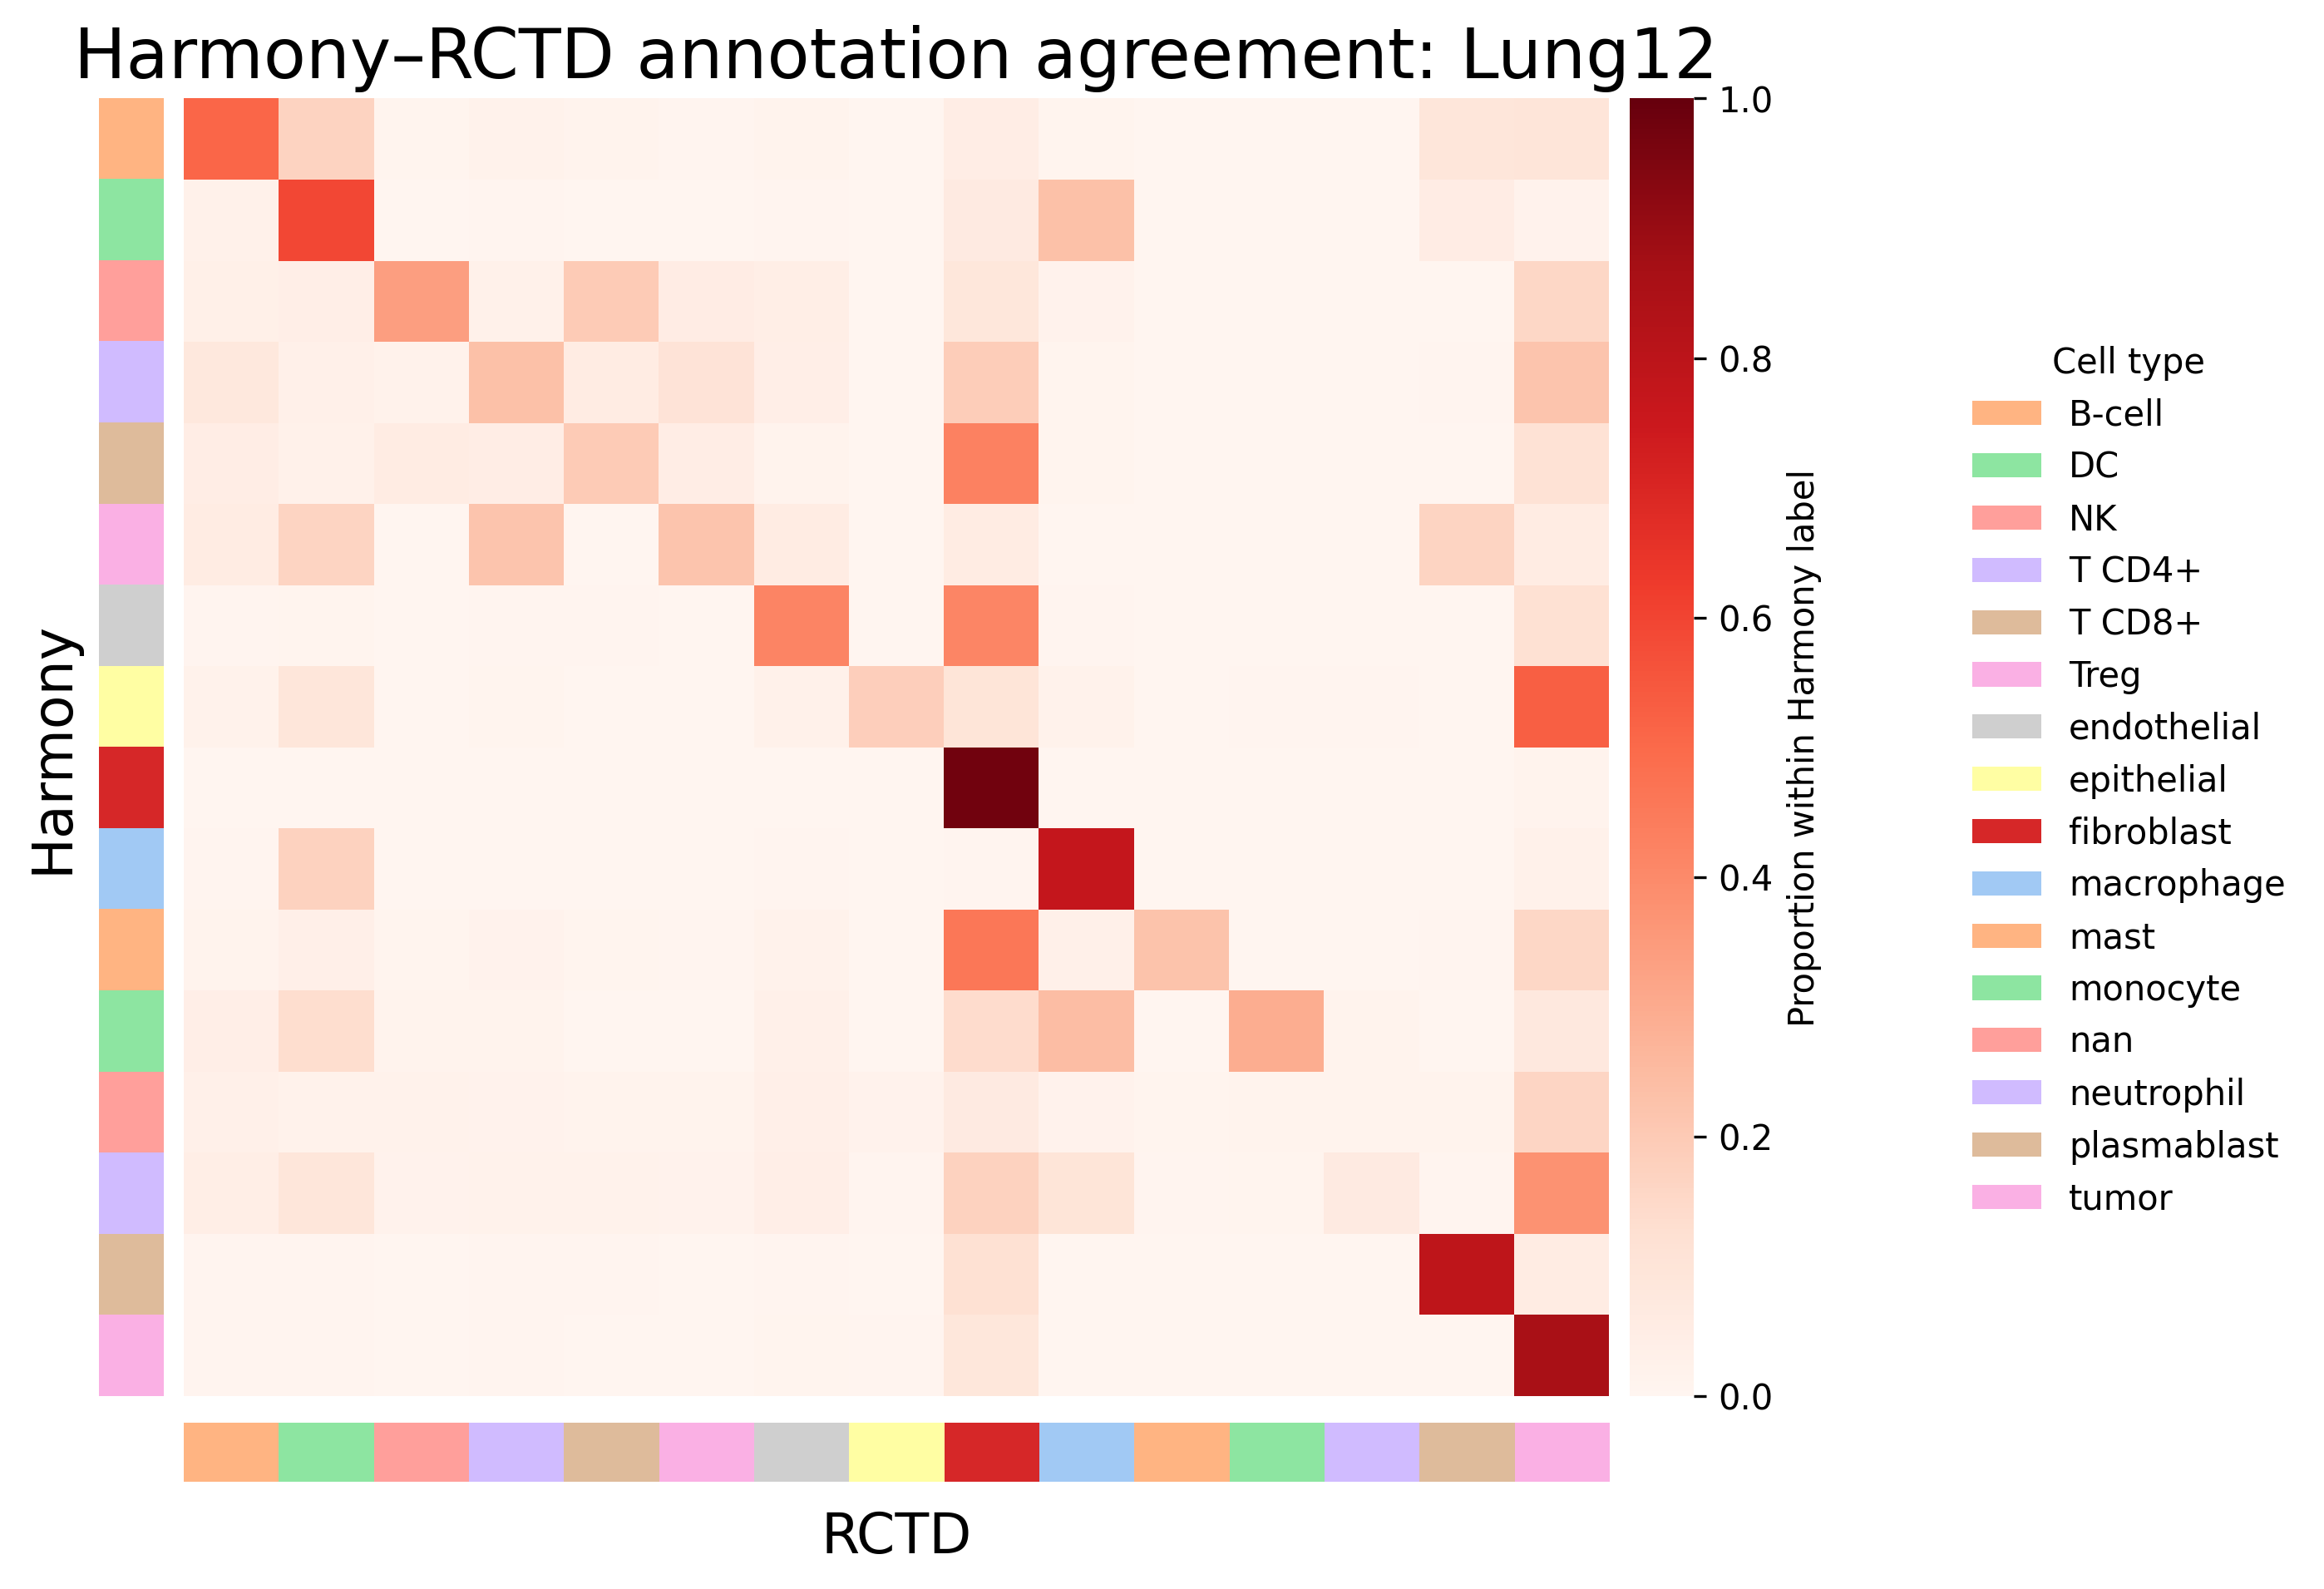

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.colors import to_rgba
from matplotlib.patches import Patch

sample = "Lung12"

sample_df = cell_agreement_df.loc[
    cell_agreement_df["sample_replicate"]
    .str.contains(sample, na=False)
].copy()

confusion_proportions = pd.crosstab(
    sample_df["cell_type"],
    sample_df["split_X_primary_cell_type"],
    normalize="index",
)
cell_type_order = sorted(list(sample_df['cell_type'].unique()))
# Preserve the same cell-type order used in your other plots
row_order = [
    cell_type
    for cell_type in cell_type_order
    if cell_type in confusion_proportions.index
]

column_order = [
    cell_type
    for cell_type in cell_type_order
    if cell_type in confusion_proportions.columns
]

confusion_proportions = confusion_proportions.reindex(
    index=row_order,
    columns=column_order,
)

# Ensure every displayed cell type has a color
all_present_types = list(
    dict.fromkeys(
        confusion_proportions.index.tolist()
        + confusion_proportions.columns.tolist()
    )
)

default_palette = sns.color_palette(
    "tab20",
    n_colors=len(all_present_types),
)

default_colors = dict(
    zip(all_present_types, default_palette)
)

existing_colors = globals().get("cell_type_colors", {})

cell_type_colors = {
    **default_colors,
    **existing_colors,
}

cell_type_colors["fibroblast"] = "#d62728"

n_rows, n_columns = confusion_proportions.shape

fig = plt.figure(
    figsize=(
        max(6, 0.55 * n_columns),
        max(6, 0.45 * n_rows),
    ),
    dpi=300,
)

# Main heatmap on top, x-axis color strip on bottom
grid = fig.add_gridspec(
    nrows=2,
    ncols=3,
    width_ratios=[0.045, 1, 0.045],
    height_ratios=[1, 0.045],
    wspace=0.04,
    hspace=0.04,
)

ax_left = fig.add_subplot(grid[0, 0])
ax_heatmap = fig.add_subplot(grid[0, 1])
ax_colorbar = fig.add_subplot(grid[0, 2])
ax_bottom = fig.add_subplot(grid[1, 1])

sns.heatmap(
    confusion_proportions,
    cmap="Reds",
    vmin=0,
    vmax=1,
    xticklabels=False,
    yticklabels=False,
    ax=ax_heatmap,
    cbar_ax=ax_colorbar,
    cbar_kws={
        "label": "Proportion within Harmony label",
    },
)

# Bottom strip: RCTD column annotations
column_color_strip = np.array([
    [
        to_rgba(cell_type_colors[cell_type])
        for cell_type in confusion_proportions.columns
    ]
])

ax_bottom.imshow(
    column_color_strip,
    aspect="auto",
    interpolation="nearest",
)

# Left strip: Harmony row annotations
row_color_strip = np.array([
    [to_rgba(cell_type_colors[cell_type])]
    for cell_type in confusion_proportions.index
])

ax_left.imshow(
    row_color_strip,
    aspect="auto",
    interpolation="nearest",
    origin="upper",
)

# Remove ticks and borders from color strips
for strip_ax in [ax_bottom, ax_left]:
    strip_ax.set_xticks([])
    strip_ax.set_yticks([])

    for spine in strip_ax.spines.values():
        spine.set_visible(False)

ax_heatmap.set_title(
    f"Harmony–RCTD annotation agreement: {sample}",
    fontsize=20
)

# Put the x-axis title beneath the bottom strip
ax_heatmap.set_xlabel("")
ax_bottom.set_xlabel(
    "RCTD",
    labelpad=8,
    fontsize=16
)

ax_heatmap.set_ylabel("Harmony",labelpad=30,fontsize=16)

# Shared legend
legend_order = [
    cell_type
    for cell_type in cell_type_order
    if cell_type in all_present_types
]

legend_handles = [
    Patch(
        facecolor=cell_type_colors[cell_type],
        edgecolor="none",
        label=cell_type,
    )
    for cell_type in legend_order
]

fig.legend(
    handles=legend_handles,
    title="Cell type",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
)

plt.show()

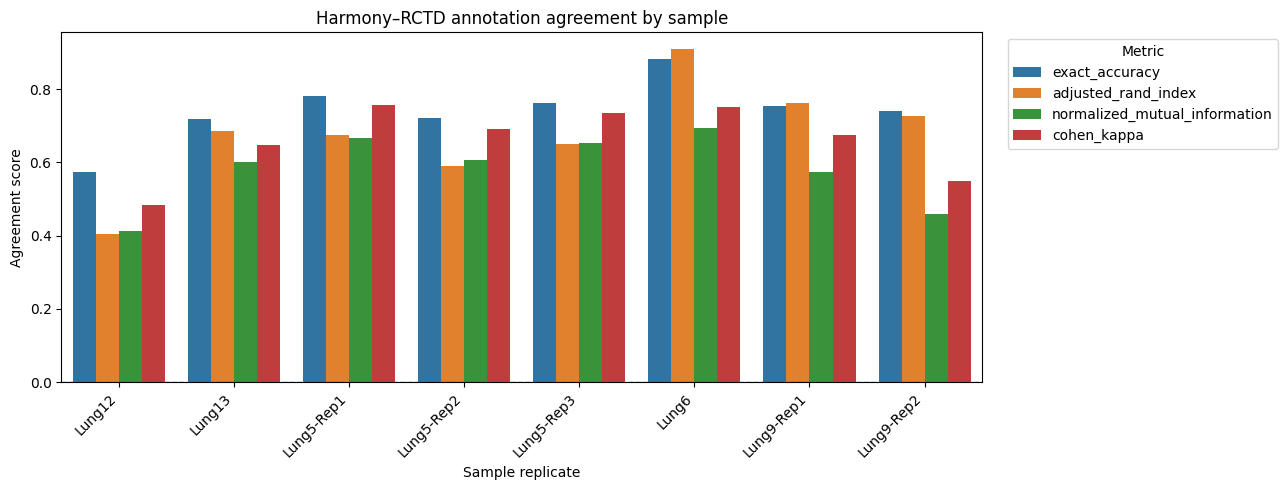

In [26]:
agreement_long = agreement_df.melt(
    id_vars=["sample_replicate", "n_cells"],
    value_vars=[
        "exact_accuracy",
        "adjusted_rand_index",
        "normalized_mutual_information",
        "cohen_kappa",
    ],
    var_name="metric",
    value_name="score",
)

plt.figure(figsize=(13, 5))

sns.barplot(
    data=agreement_long,
    x="sample_replicate",
    y="score",
    hue="metric",
)

plt.axhline(0, linestyle="--", linewidth=1)
plt.xlabel("Sample replicate")
plt.ylabel("Agreement score")
plt.title("Harmony–RCTD annotation agreement by sample")
plt.xticks(rotation=45, ha="right")
plt.legend(
    title="Metric",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)
plt.tight_layout()
plt.show()

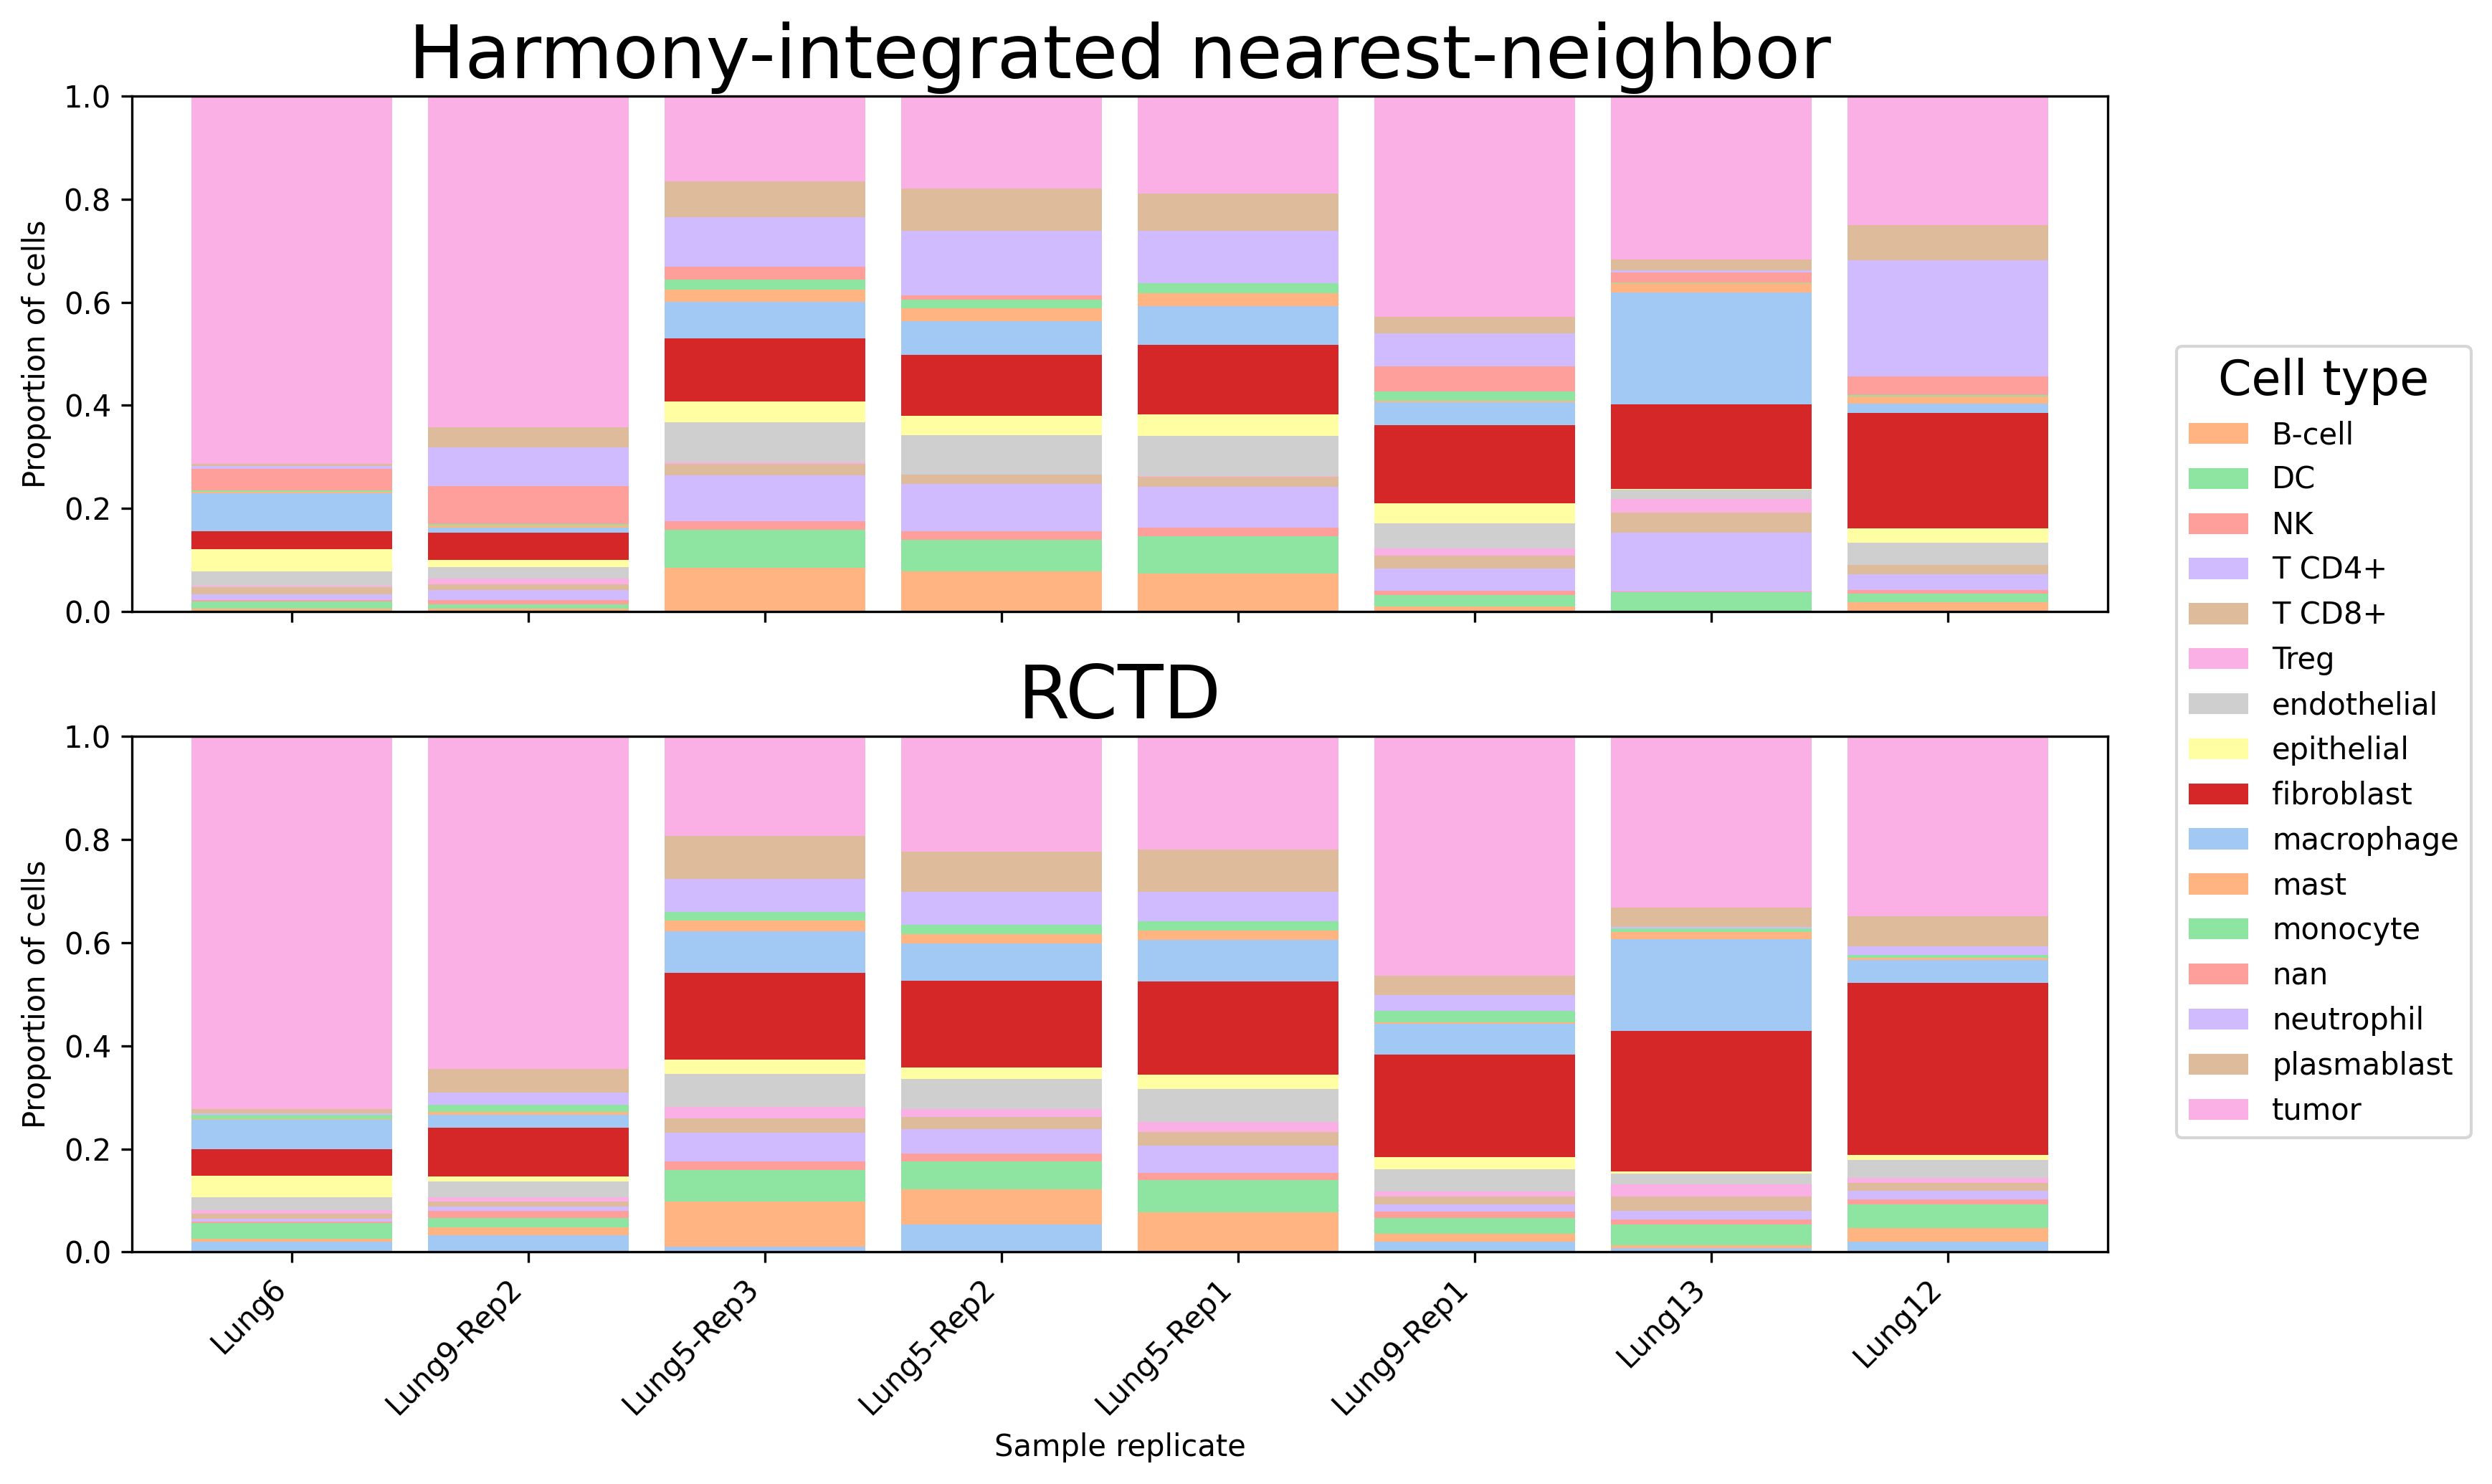

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

annotation_methods = [
    "cell_type",
    "split_X_primary_cell_type",
]

method_titles = {
    "cell_type": "Harmony-integrated nearest-neighbor",
    "split_X_primary_cell_type": "RCTD",
}

# Keep both annotation methods
plot_df = results.loc[
    results["annotation_method"].isin(annotation_methods)
].copy()

# Total number of cells for each sample and annotation method
sample_totals = (
    plot_df
    .groupby(
        ["annotation_method", "sample_replicate"],
        observed=True,
    )["count"]
    .transform("sum")
)

plot_df["cell_type_proportion"] = (
    plot_df["count"] / sample_totals
)

# Create one wide table for each annotation method
wide_tables = {}

for method in annotation_methods:
    wide_tables[method] = (
        plot_df.loc[
            plot_df["annotation_method"].eq(method)
        ]
        .pivot_table(
            index="sample_replicate",
            columns="cell_type",
            values="cell_type_proportion",
            fill_value=0,
            observed=True,
        )
    )

rctd_wide = wide_tables["split_X_primary_cell_type"]

# if "fibroblast of lung" not in rctd_wide.columns:
#     raise KeyError(
#         "'fibroblast of lung' is not present in the RCTD annotations."
#     )

# Ascending RCTD fibroblast proportion
sample_order = (
    rctd_wide["fibroblast"]
    .sort_values(ascending=True)
    .index
    .tolist()
)

# # Force B15 to the final position
# if "B15" in sample_order:
#     sample_order.remove("B15")
#     sample_order.append("B15")

# Union of cell types used by either annotation method
cell_type_order = sorted(
    set(wide_tables["cell_type"].columns)
    | set(wide_tables["split_X_primary_cell_type"].columns)
)

# Assign colors in the existing cell_type_order
other_colors = sns.color_palette(
    "pastel",
    n_colors=len(cell_type_order),
)

cell_type_colors = dict(
    zip(cell_type_order, other_colors)
)

cell_type_colors["fibroblast"] = "#d62728"

colors = [
    cell_type_colors[cell_type]
    for cell_type in cell_type_order
]

# Ensure samples and cell types have the same ordering
for method in annotation_methods:
    wide_tables[method] = (
        wide_tables[method]
        .reindex(
            index=sample_order,
            columns=cell_type_order,
            fill_value=0,
        )
    )

# colors = sns.color_palette(
#     "tab20",
#     n_colors=len(cell_type_order),
# )

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(10, 7),
    sharex=True,
    sharey=True,
    dpi=300
)

for ax, method in zip(axes, annotation_methods):
    wide_tables[method].plot(
        kind="bar",
        stacked=True,
        width=0.85,
        color=colors,
        ax=ax,
        legend=False,
    )

    ax.set_title(method_titles[method],fontsize=25)
    ax.set_xlabel("")
    ax.set_ylabel("Proportion of cells")
    ax.set_ylim(0, 1)

axes[-1].set_xlabel("Sample replicate")
axes[-1].tick_params(
    axis="x",
    rotation=45,
)

for label in axes[-1].get_xticklabels():
    label.set_horizontalalignment("right")

# Single shared legend
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Cell type",
    bbox_to_anchor=(1.01, 0.5),
    loc="center left",
    title_fontsize=16,
)

# fig.suptitle(
#     "Cell-type composition by annotation method",
#     fontsize=30,
#     y=1.01,
# )

plt.tight_layout()
plt.show()

In [63]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Summarize total cells and T cells for each sample replicate
tcell_summary = (
    results
    .groupby("sample_replicate", observed=True)
    .apply(
        lambda df: pd.Series({
            "total_cells": df["count"].sum(),
            "tcell_total": df.loc[df["is_tcell"], "count"].sum(),
        }),
        include_groups=False,
    )
    .reset_index()
)

tcell_summary["non_tcell_total"] = (
    tcell_summary["total_cells"] - tcell_summary["tcell_total"]
)

tcell_summary["tcell_proportion"] = (
    tcell_summary["tcell_total"] / tcell_summary["total_cells"]
)

# Optional percentage column for display
tcell_summary["tcell_percent"] = (
    100 * tcell_summary["tcell_proportion"]
)

# Sort samples by T-cell proportion
tcell_summary = tcell_summary.sort_values(
    "tcell_proportion",
    ascending=False,
).reset_index(drop=True)

tcell_summary

,sample_replicate,total_cells,tcell_total,non_tcell_total,tcell_proportion,tcell_percent
0,B12,295024,192577,102447,0.652750,65.275028
1,B8,95194,60773,34421,0.638412,63.841208
2,B9,179782,113864,65918,0.633345,63.334483
3,B14,150652,94219,56433,0.625408,62.540823
4,B5,357852,214212,143640,0.598605,59.860501
5,B11,150254,87874,62380,0.584836,58.483634
6,B2,258160,143244,114916,0.554865,55.486520
7,B3,244770,131768,113002,0.538334,53.833395
8,B7,96772,51234,45538,0.529430,52.943000
9,B6,185374,92338,93036,0.498117,49.811732


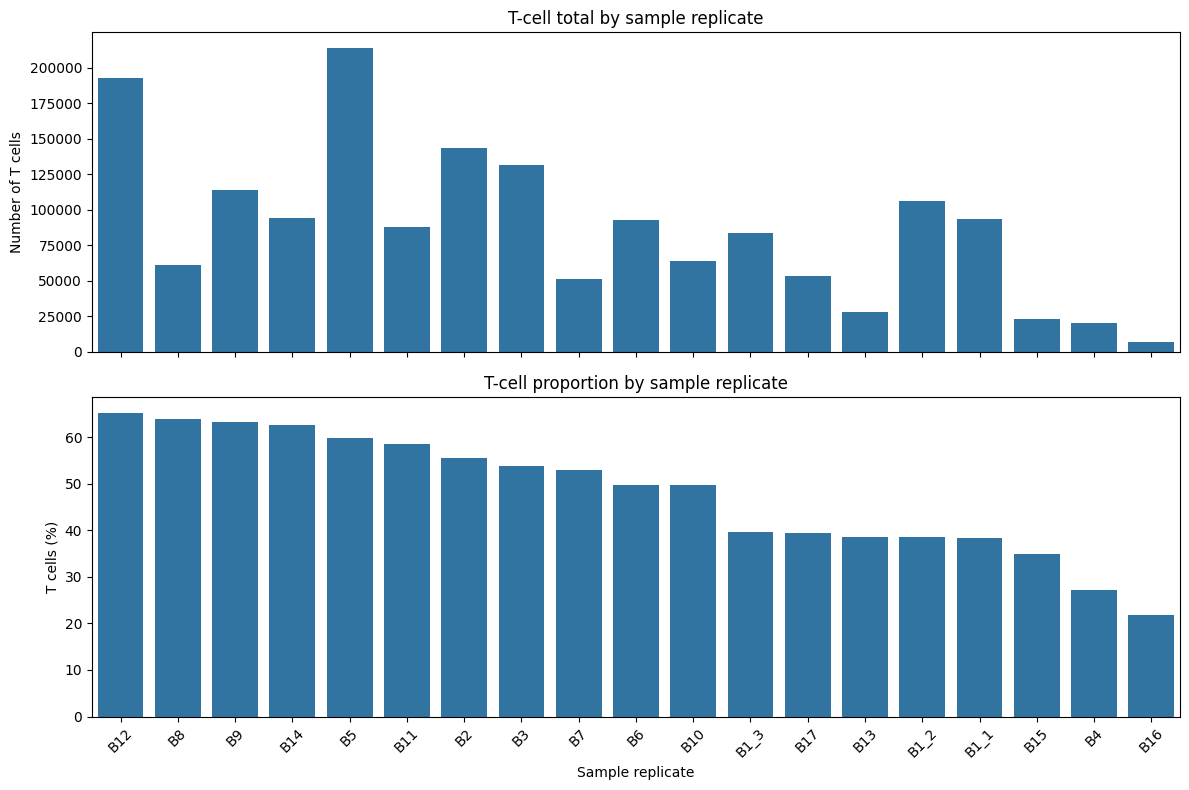

In [64]:
sample_order = tcell_summary["sample_replicate"]

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(12, 8),
    sharex=True,
)

# Absolute T-cell counts
sns.barplot(
    data=tcell_summary,
    x="sample_replicate",
    y="tcell_total",
    order=sample_order,
    ax=axes[0],
)

axes[0].set_title("T-cell total by sample replicate")
axes[0].set_xlabel("")
axes[0].set_ylabel("Number of T cells")

# T-cell proportions
sns.barplot(
    data=tcell_summary,
    x="sample_replicate",
    y="tcell_percent",
    order=sample_order,
    ax=axes[1],
)

axes[1].set_title("T-cell proportion by sample replicate")
axes[1].set_xlabel("Sample replicate")
axes[1].set_ylabel("T cells (%)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()